## 1. Imports & constants

In [ ]:
import json, os, random
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)

DATA_ROOT = Path('/kaggle/input/competitions/pose-estimation/archive (2)/dataset')
ANN_DIR   = DATA_ROOT / 'annotations_trainval2017'
TRAIN_DIR = DATA_ROOT / 'train'
VAL_DIR   = DATA_ROOT / 'val'

WORK = Path('/kaggle/working'); WORK.mkdir(exist_ok=True)

KP_NAMES = [
    'nose', 'left_eye', 'right_eye', 'left_ear', 'right_ear',
    'left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow',
    'left_wrist', 'right_wrist', 'left_hip', 'right_hip',
    'left_knee', 'right_knee', 'left_ankle', 'right_ankle',
]
NUM_KP = 17

COCO_SIGMAS = np.array([
    .026, .025, .025, .035, .035,   # nose, eyes, ears
    .079, .079, .072, .072,          # shoulders, elbows
    .062, .062, .107, .107,          # wrists, hips
    .087, .087, .089, .089,          # knees, ankles
])

FLIP_PAIRS = [(1, 2), (3, 4), (5, 6), (7, 8), (9, 10), (11, 12), (13, 14), (15, 16)]
FLIP_IDX = list(range(NUM_KP))
for l, r in FLIP_PAIRS:
    FLIP_IDX[l], FLIP_IDX[r] = r, l
FLIP_IDX = np.array(FLIP_IDX)
print("FLIP_IDX:", FLIP_IDX.tolist())


FLIP_IDX: [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]


## 2. Load annotations & filter

In [11]:
def load_split(json_path, img_dir):
    with open(json_path) as f:
        coco = json.load(f)
    files_on_disk = set(os.listdir(img_dir))
    id2img = {im['id']: im for im in coco['images'] if im['file_name'] in files_on_disk}
    anns = [a for a in coco['annotations']
            if a['image_id'] in id2img and a.get('num_keypoints', 0) > 0]
    print(f"  {json_path.name}: {len(id2img)} images, {len(anns)} usable persons "
          f"(of {len(coco['annotations'])} total anns)")
    return id2img, anns

print("TRAIN:")
train_imgs, train_anns = load_split(ANN_DIR / 'person_keypoints_train2017.json', TRAIN_DIR)
print("VAL (held-out test):")
test_imgs,  test_anns  = load_split(ANN_DIR / 'person_keypoints_val2017.json',   VAL_DIR)


TRAIN:
  person_keypoints_train2017.json: 64115 images, 149813 usable persons (of 262465 total anns)
VAL (held-out test):
  person_keypoints_val2017.json: 2693 images, 6352 usable persons (of 11004 total anns)


In [34]:
train_image_ids = sorted(train_imgs.keys())
rng = np.random.RandomState(SEED)
rng.shuffle(train_image_ids)
n_val = int(0.10 * len(train_image_ids))
val_ids   = set(train_image_ids[:n_val])
train_ids = set(train_image_ids[n_val:])

tr_anns  = [a for a in train_anns if a['image_id'] in train_ids]
val_anns = [a for a in train_anns if a['image_id'] in val_ids]

print(f"split:  train  = {len(train_ids):>5} imgs, {len(tr_anns):>6} persons")
print(f"        val    = {len(val_ids):>5} imgs, {len(val_anns):>6} persons")
print(f"        test   = {len(test_imgs):>5} imgs, {len(test_anns):>6} persons   (COCO val2017 hold-out)")

split:  train  = 57704 imgs, 135082 persons
        val    =  6411 imgs,  14731 persons
        test   =  2693 imgs,   6352 persons   (COCO val2017 hold-out)


## 4. OKS metric

$$
\mathrm{OKS}(\hat p, p, s) \;=\; \frac{\sum_k \exp\!\left(-\dfrac{d_k^2}{2\,s^2\,\sigma_k^2}\right)\delta(v_k>0)}{\sum_k \delta(v_k>0)}
$$

In [14]:
def oks_per_kp(pred_xy, gt_kp, area, sigmas=COCO_SIGMAS):
    pred = np.asarray(pred_xy, dtype=float).reshape(NUM_KP, 2)
    gt   = np.asarray(gt_kp,   dtype=float).reshape(NUM_KP, 3)
    out  = np.full(NUM_KP, np.nan)
    mask = gt[:, 2] > 0
    if mask.any():
        d2 = ((pred[mask] - gt[mask, :2]) ** 2).sum(axis=1)
        out[mask] = np.exp(-d2 / (2 * area * sigmas[mask] ** 2))
    return out


def oks_single(pred_xy, gt_kp, area, sigmas=COCO_SIGMAS):
    """OKS scalar in [0, 1]; NaN if no labeled kp."""
    sims = oks_per_kp(pred_xy, gt_kp, area, sigmas)
    return float(np.nanmean(sims)) if np.isfinite(sims).any() else np.nan


def oks_batch(pred_xy_arr, gt_kp_arr, areas, sigmas=COCO_SIGMAS):
    pred  = np.asarray(pred_xy_arr, dtype=float)
    gt    = np.asarray(gt_kp_arr,   dtype=float)
    areas = np.asarray(areas,       dtype=float)
    v     = gt[..., 2]
    d2    = ((pred - gt[..., :2]) ** 2).sum(axis=-1)      
    e     = d2 / (2 * areas[:, None] * sigmas[None, :] ** 2) 
    sim   = np.exp(-e)
    mask  = v > 0
    sim_masked = np.where(mask, sim, 0.0)
    counts     = mask.sum(axis=1)
    oks        = np.where(counts > 0, sim_masked.sum(axis=1) / np.maximum(counts, 1), np.nan)
    return oks


## Pretrained YOLOv8-pose baseline (zero-shot)

In [17]:
!pip install -q ultralytics
import torch
from ultralytics import YOLO
print("ultralytics OK,  CUDA:", torch.cuda.is_available(), " GPUs:", torch.cuda.device_count())


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 22.5 MB/s eta 0:00:00a 0:00:01
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics OK,  CUDA: True  GPUs: 2


In [18]:
def bbox_iou_xywh(a, b):
    """IoU between bbox in [x,y,w,h] (single 'a') and array of bboxes [x,y,w,h] (b: (M,4)). Returns (M,)."""
    ax, ay, aw, ah = a
    a_x2, a_y2 = ax + aw, ay + ah
    bx, by, bw, bh = b[:, 0], b[:, 1], b[:, 2], b[:, 3]
    b_x2, b_y2 = bx + bw, by + bh
    ix1 = np.maximum(ax, bx); iy1 = np.maximum(ay, by)
    ix2 = np.minimum(a_x2, b_x2); iy2 = np.minimum(a_y2, b_y2)
    iw = np.clip(ix2 - ix1, 0, None); ih = np.clip(iy2 - iy1, 0, None)
    inter = iw * ih
    union = aw * ah + bw * bh - inter
    return inter / np.maximum(union, 1e-9)


def evaluate_predictions(anns, image_root, predict_image_fn, iou_thresh=0.5):
    """Generic evaluator.
    predict_image_fn(image_path) -> (boxes_xywh: (M,4), kpts_xy: (M,17,2)) for that image.
    For each ann we pick the best-IoU prediction; if none ≥ iou_thresh, we fall back."""
    by_img = defaultdict(list)
    for a in anns: by_img[a['image_id']].append(a)
    id2file = {**train_imgs, **test_imgs}

    all_pred_xy, all_gt, all_area, hit = [], [], [], []
    for img_id, ann_list in by_img.items():
        path = Path(image_root) / id2file[img_id]['file_name']
        boxes, kpts = predict_image_fn(str(path))
        for a in ann_list:
            gt_xyv = np.array(a['keypoints']).reshape(NUM_KP, 3)
            if len(boxes) > 0:
                ious = bbox_iou_xywh(a['bbox'], boxes)
                j = int(ious.argmax()); best_iou = float(ious[j])
            else:
                best_iou = 0.0
            if best_iou >= iou_thresh:
                pred_xy = kpts[j]; hit.append(1)
            else:
                pred_xy = np.zeros((NUM_KP, 2))
                hit.append(0)
            all_pred_xy.append(pred_xy); all_gt.append(gt_xyv); all_area.append(a['area'])

    pred_arr = np.stack(all_pred_xy); gt_arr = np.stack(all_gt); area_arr = np.array(all_area)
    oks = oks_batch(pred_arr, gt_arr, area_arr)
    summary = dict(
        n_persons=len(all_pred_xy),
        match_rate=float(np.mean(hit)),
        mean_oks=float(np.nanmean(oks)),
        ap50=float((oks >= 0.50).mean()),
        ap75=float((oks >= 0.75).mean()),
        ap_5095=float(np.mean([(oks >= t).mean() for t in np.arange(.5, 1., .05)])),
    )
    return summary, oks, pred_arr, gt_arr, area_arr


In [ ]:
from tqdm.auto import tqdm

yolo = YOLO('yolov8m-pose.pt')

def predict_with_yolo_factory(model, conf=0.25, iou=0.7):
    """Returns predict_image_fn that pulls (boxes_xywh, kpts_xy) from cached results dict."""
    cache = {}
    def fn(path):
        if path not in cache:
            r = model.predict(path, conf=conf, iou=iou, verbose=False, device=0)[0]
            if r.boxes is None or len(r.boxes) == 0:
                cache[path] = (np.empty((0, 4)), np.empty((0, NUM_KP, 2)))
            else:
                xyxy  = r.boxes.xyxy.cpu().numpy()
                boxes = np.stack([xyxy[:, 0], xyxy[:, 1], xyxy[:, 2] - xyxy[:, 0], xyxy[:, 3] - xyxy[:, 1]], axis=1)
                kpts  = r.keypoints.xy.cpu().numpy() if r.keypoints is not None else np.zeros((len(boxes), NUM_KP, 2))
                cache[path] = (boxes, kpts)
        return cache[path]
    return fn

predict_yolo = predict_with_yolo_factory(yolo)

smoke: /kaggle/input/competitions/pose-estimation/archive (2)/dataset/val/000000397133.jpg
  detections: 2,  kpts shape: (2, 17, 2)


In [ ]:
test_paths = [str(VAL_DIR / im['file_name']) for im in test_imgs.values()]

print(f"Running YOLOv8m-pose on {len(test_paths)} test images...")
for p in tqdm(test_paths):
    predict_yolo(p) 

print("\nScoring...")
summary_pre_test, oks_pre_test, pp, gg, aa = evaluate_predictions(test_anns, VAL_DIR, predict_yolo)
print("\nYOLOv8m-pose pretrained (zero-shot) on TEST (val2017 hold-out):")
for k, v in summary_pre_test.items():
    print(f"  {k:<12} = {v:.4f}" if isinstance(v, float) else f"  {k:<12} = {v}")


Running YOLOv8m-pose on 2693 test images...


  0%|          | 0/2693 [00:00<?, ?it/s]


Scoring...

YOLOv8m-pose pretrained (zero-shot) on TEST (val2017 hold-out):
  n_persons    = 6352
  match_rate   = 0.9259
  mean_oks     = 0.5937
  ap50         = 0.7188
  ap75         = 0.3563
  ap_5095      = 0.3783


## Fine-tuning preparations

In [21]:
WORK_DS   = WORK / 'coco_pose_local'
IMG_TRAIN = WORK_DS / 'images' / 'train';  IMG_VAL = WORK_DS / 'images' / 'val'
LBL_TRAIN = WORK_DS / 'labels' / 'train';  LBL_VAL = WORK_DS / 'labels' / 'val'
for d in (IMG_TRAIN, IMG_VAL, LBL_TRAIN, LBL_VAL):
    d.mkdir(parents=True, exist_ok=True)


def coco_to_yolo_lines(anns_for_img, w, h):
    """Convert COCO anns for one image to YOLO-pose label lines (normalized)."""
    lines = []
    for a in anns_for_img:
        x, y, bw, bh = a['bbox']
        cx = np.clip((x + bw / 2) / w, 0, 1)
        cy = np.clip((y + bh / 2) / h, 0, 1)
        nw = np.clip(bw / w, 0, 1);  nh = np.clip(bh / h, 0, 1)
        kp = np.asarray(a['keypoints'], dtype=float).reshape(NUM_KP, 3)
        kp[:, 0] = np.clip(kp[:, 0] / w, 0, 1)
        kp[:, 1] = np.clip(kp[:, 1] / h, 0, 1)
        kp[kp[:, 2] == 0, :2] = 0 
        kp_str = " ".join(f"{v:.6f}" for v in kp.ravel())
        lines.append(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f} {kp_str}")
    return lines


# Group anns by image_id 
ann_by_img = defaultdict(list)
for a in train_anns:
    ann_by_img[a['image_id']].append(a)

for split_ids, lbl_dir, img_dir, name in [
    (train_ids, LBL_TRAIN, IMG_TRAIN, 'train'),
    (val_ids,   LBL_VAL,   IMG_VAL,   'val'),
]:
    for img_id in tqdm(split_ids, desc=name):
        im   = train_imgs[img_id]
        link = img_dir / im['file_name']
        lbl  = lbl_dir / (Path(im['file_name']).stem + '.txt')
        if not link.exists():
            link.symlink_to(TRAIN_DIR / im['file_name'])
        if not lbl.exists():
            lbl.write_text("\n".join(coco_to_yolo_lines(ann_by_img[img_id], im['width'], im['height'])) + "\n")

print(f"\ntrain images: {len(list(IMG_TRAIN.iterdir()))},  labels: {len(list(LBL_TRAIN.iterdir()))}")
print(f"val   images: {len(list(IMG_VAL.iterdir()))},  labels: {len(list(LBL_VAL.iterdir()))}")
print("\nsample label (first line):")
print(next(iter(LBL_TRAIN.iterdir())).read_text().splitlines()[0][:200], "...")


train:   0%|          | 0/57704 [00:00<?, ?it/s]

val:   0%|          | 0/6411 [00:00<?, ?it/s]


train images: 57704,  labels: 57704
val   images: 6411,  labels: 6411

sample label (first line):
0 0.830422 0.465172 0.133817 0.296563 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.807963 0.343750 2.000000 0.843091 0.343750 2.000000 0.798595 0.375000 2.000000  ...


In [22]:
# Local YAML config — no `download:` field, paths point to our symlinked structure.
yaml_path = WORK_DS / 'coco-pose-local.yaml'
yaml_path.write_text(
    f"path: {WORK_DS}\n"
    f"train: images/train\n"
    f"val:   images/val\n"
    f"kpt_shape: [17, 3]\n"
    f"flip_idx: {FLIP_IDX.tolist()}\n"
    f"names:\n  0: person\n"
)
print(yaml_path.read_text())


path: /kaggle/working/coco_pose_local
train: images/train
val:   images/val
kpt_shape: [17, 3]
flip_idx: [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]
names:
  0: person



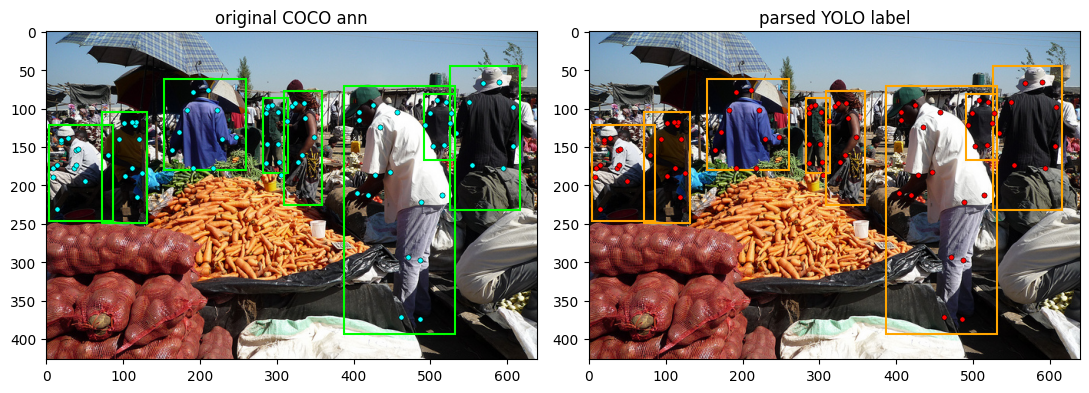

If both panels show identical bboxes & keypoints, labels are correctly normalized.


In [23]:
# Sanity check: load 1 train image, parse its YOLO label, draw bbox + kp.
# If labels are correct, the right plot must look identical to the left (original COCO).
import matplotlib.image as mpimg

sid = next(iter(train_ids))
im_meta  = train_imgs[sid]
img_path = IMG_TRAIN / im_meta['file_name']
lbl_path = LBL_TRAIN / (Path(im_meta['file_name']).stem + '.txt')
img = mpimg.imread(img_path);  H, W = img.shape[:2]

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(img); ax[0].set_title('original COCO ann')
for a in ann_by_img[sid]:
    x, y, w, h = a['bbox']
    ax[0].add_patch(plt.Rectangle((x, y), w, h, fill=False, ec='lime', lw=1.5))
    kp = np.array(a['keypoints']).reshape(NUM_KP, 3)
    m = kp[:, 2] > 0
    ax[0].scatter(kp[m, 0], kp[m, 1], c='cyan', s=14, ec='k', lw=0.4)

ax[1].imshow(img); ax[1].set_title('parsed YOLO label')
for line in lbl_path.read_text().strip().splitlines():
    vals = line.split()
    cx, cy, nw, nh = (float(v) for v in vals[1:5])
    cx, cy, nw, nh = cx * W, cy * H, nw * W, nh * H
    ax[1].add_patch(plt.Rectangle((cx - nw / 2, cy - nh / 2), nw, nh, fill=False, ec='orange', lw=1.5))
    kp = np.array([float(v) for v in vals[5:]]).reshape(NUM_KP, 3)
    kp[:, 0] *= W;  kp[:, 1] *= H
    m = kp[:, 2] > 0
    ax[1].scatter(kp[m, 0], kp[m, 1], c='red', s=14, ec='k', lw=0.4)

plt.tight_layout(); plt.show()


## Fine-tune YOLOv8m-pose

In [ ]:
RUNS_DIR = WORK / 'yolo_runs'
RUN_NAME = 'm_pose_ft_full'

ft_yolo = YOLO('yolov8m-pose.pt')

results = ft_yolo.train(
    data       = str(yaml_path),
    epochs     = 3,
    imgsz      = 640,
    batch      = 16,                
    device     = 0,               
    workers    = 4,
    project    = str(RUNS_DIR),
    name       = RUN_NAME,
    exist_ok   = True,
    seed       = SEED,
    optimizer  = 'SGD',
    lr0        = 0.001, lrf=0.01, momentum=0.937, weight_decay=0.0005,
    cos_lr     = True,
    # augmentations
    fliplr     = 0.5,                 
    scale      = 0.5, translate=0.1, degrees=0.0,
    hsv_h      = 0.015, hsv_s=0.7, hsv_v=0.4,
    mosaic     = 0.0, mixup=0.0,
    plots      = True, save=True, verbose=True,
)
print("\nbest weights:", Path(results.save_dir) / 'weights' / 'best.pt')


Ultralytics 8.4.42 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/coco_pose_local/coco-pose-local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m-pose.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=m_pose_ft_full, nbs=64, nms=False, opset=None, optimize=False, optimizer=SGD, o

In [27]:
best_pt = RUNS_DIR / RUN_NAME / 'weights' / 'best.pt'
ft_model = YOLO(str(best_pt))
predict_yolo_ft = predict_with_yolo_factory(ft_model)

# Run on test (val2017 hold-out) — fresh cache, separate from pretrained.
print(f"Inference of fine-tuned model on {len(test_paths)} test images...")
for p in tqdm(test_paths):
    predict_yolo_ft(p)

summary_ft_test, oks_ft_test, *_ = evaluate_predictions(test_anns, VAL_DIR, predict_yolo_ft)
print("\nYOLOv8m-pose FINE-TUNED on TEST (val2017 hold-out):")
for k, v in summary_ft_test.items():
    print(f"  {k:<12} = {v:.4f}" if isinstance(v, float) else f"  {k:<12} = {v}")

print("\n────────  pretrained vs fine-tuned (test=val2017)  ────────")
for k in ['mean_oks', 'ap50', 'ap75', 'ap_5095', 'match_rate']:
    pre, ft = summary_pre_test[k], summary_ft_test[k]
    print(f"  {k:<12}  pretrained={pre:.4f}  fine-tuned={ft:.4f}  Δ={ft-pre:+.4f}")


Inference of fine-tuned model on 2693 test images...


  0%|          | 0/2693 [00:00<?, ?it/s]


YOLOv8m-pose FINE-TUNED on TEST (val2017 hold-out):
  n_persons    = 6352
  match_rate   = 0.9090
  mean_oks     = 0.5713
  ap50         = 0.6924
  ap75         = 0.3180
  ap_5095      = 0.3518

────────  pretrained vs fine-tuned (test=val2017)  ────────
  mean_oks      pretrained=0.5937  fine-tuned=0.5713  Δ=-0.0224
  ap50          pretrained=0.7188  fine-tuned=0.6924  Δ=-0.0264
  ap75          pretrained=0.3563  fine-tuned=0.3180  Δ=-0.0383
  ap_5095       pretrained=0.3783  fine-tuned=0.3518  Δ=-0.0266
  match_rate    pretrained=0.9259  fine-tuned=0.9090  Δ=-0.0168


### Corrected fine-tune run (low LR + frozen backbone)

In [29]:
RUN_NAME_V2 = 'm_pose_ft_lowlr_frozen'
ft_yolo_v2 = YOLO('yolov8m-pose.pt')

results_v2 = ft_yolo_v2.train(
    data       = str(yaml_path),
    epochs     = 2,
    imgsz      = 640,
    batch      = 16,
    device     = 0,
    workers    = 4,
    project    = str(RUNS_DIR),
    name       = RUN_NAME_V2,
    exist_ok   = True,
    seed       = SEED,
    optimizer  = 'SGD',
    lr0        = 1e-4,                  
    lrf        = 0.1,
    momentum   = 0.937, weight_decay=0.0005,
    cos_lr     = True,
    freeze     = 10,                    
    # augmentations
    fliplr     = 0.5,
    scale      = 0.3, translate=0.1, degrees=0.0,
    hsv_h      = 0.015, hsv_s=0.7, hsv_v=0.4,
    mosaic     = 0.5, mixup=0.0,
    plots      = True, save=True, verbose=True,
)
print("\nbest weights v2:", Path(results_v2.save_dir) / 'weights' / 'best.pt')


Ultralytics 8.4.42 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/coco_pose_local/coco-pose-local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m-pose.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=m_pose_ft_lowlr_frozen, nbs=64, nms=False, opset=None, optimize=False, optimizer=

In [30]:
best_pt_v2 = RUNS_DIR / RUN_NAME_V2 / 'weights' / 'best.pt'
ft_model_v2 = YOLO(str(best_pt_v2))
predict_yolo_ft_v2 = predict_with_yolo_factory(ft_model_v2)

print(f"Inference of fine-tuned v2 on {len(test_paths)} test images...")
for p in tqdm(test_paths):
    predict_yolo_ft_v2(p)

summary_ft_v2_test, oks_ft_v2_test, *_ = evaluate_predictions(test_anns, VAL_DIR, predict_yolo_ft_v2)
print("\nYOLOv8m-pose FINE-TUNED v2 (low LR + frozen backbone) on TEST:")
for k, v in summary_ft_v2_test.items():
    print(f"  {k:<12} = {v:.4f}" if isinstance(v, float) else f"  {k:<12} = {v}")

# 3-way comparison
print("\n────────  3-way comparison on TEST = val2017 hold-out  ────────")
print(f"  {'metric':<12} {'pretrained':>11} {'ft_v1_high_lr':>15} {'ft_v2_low_lr':>14}")
for k in ['mean_oks', 'ap50', 'ap75', 'ap_5095', 'match_rate']:
    print(f"  {k:<12} {summary_pre_test[k]:>11.4f} {summary_ft_test[k]:>15.4f} {summary_ft_v2_test[k]:>14.4f}")


Inference of fine-tuned v2 on 2693 test images...


  0%|          | 0/2693 [00:00<?, ?it/s]


YOLOv8m-pose FINE-TUNED v2 (low LR + frozen backbone) on TEST:
  n_persons    = 6352
  match_rate   = 0.9208
  mean_oks     = 0.5884
  ap50         = 0.7163
  ap75         = 0.3449
  ap_5095      = 0.3711

────────  3-way comparison on TEST = val2017 hold-out  ────────
  metric        pretrained   ft_v1_high_lr   ft_v2_low_lr
  mean_oks          0.5937          0.5713         0.5884
  ap50              0.7188          0.6924         0.7163
  ap75              0.3563          0.3180         0.3449
  ap_5095           0.3783          0.3518         0.3711
  match_rate        0.9259          0.9090         0.9208


### Training / validation loss & metric curves

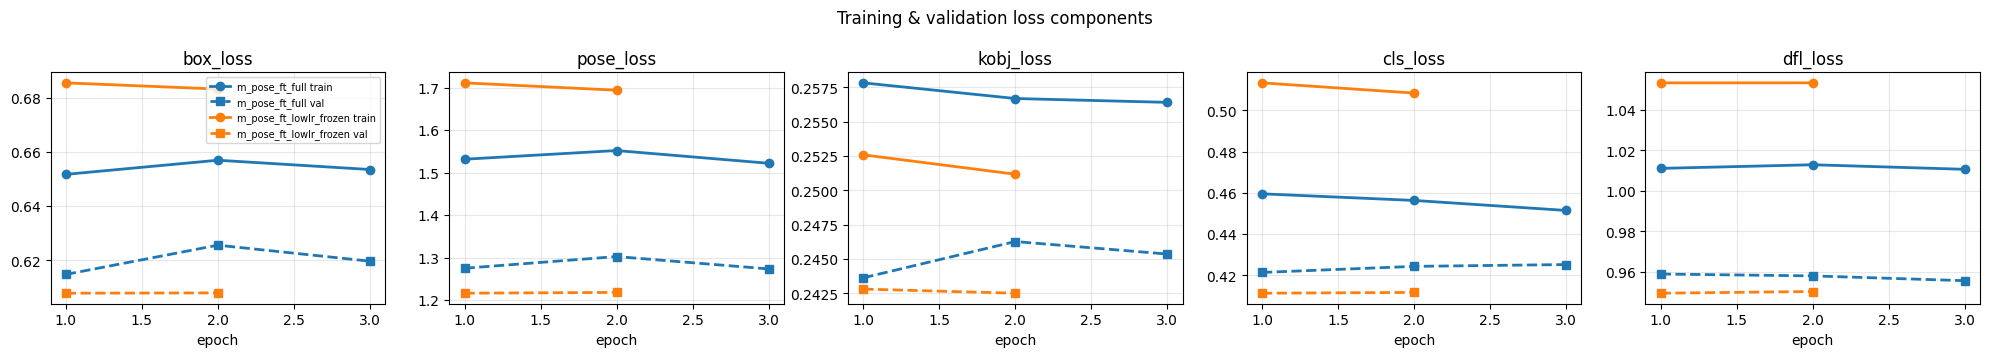

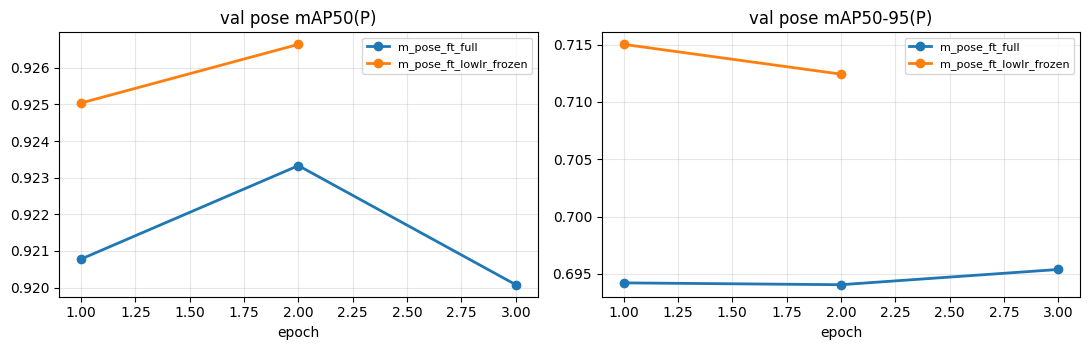

In [35]:
import pandas as pd

def load_results(run_name):
    p = RUNS_DIR / run_name / 'results.csv'
    if not p.exists(): return None
    df = pd.read_csv(p)
    df.columns = [c.strip() for c in df.columns]
    return df

dfs = {n: load_results(n) for n in [RUN_NAME, RUN_NAME_V2]}
dfs = {n: d for n, d in dfs.items() if d is not None}

# 1) Five loss components — train (solid) vs val (dashed), both runs on each subplot
loss_keys = ['box_loss', 'pose_loss', 'kobj_loss', 'cls_loss', 'dfl_loss']
colors    = {RUN_NAME: 'tab:blue', RUN_NAME_V2: 'tab:orange'}
fig, axes = plt.subplots(1, len(loss_keys), figsize=(20, 3.6))
for ax, lk in zip(axes, loss_keys):
    for n, df in dfs.items():
        c = colors[n]
        if f'train/{lk}' in df.columns:
            ax.plot(df['epoch'], df[f'train/{lk}'], color=c, lw=2, marker='o', label=f'{n} train')
        if f'val/{lk}' in df.columns:
            ax.plot(df['epoch'], df[f'val/{lk}'],   color=c, lw=2, marker='s', ls='--', label=f'{n} val')
    ax.set_title(lk); ax.set_xlabel('epoch'); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7, loc='best')
plt.suptitle('Training & validation loss components')
plt.tight_layout(); plt.show()

# 2) Pose-specific metrics on local val (mAP50 / mAP50-95)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, mk in zip(axes, ['mAP50(P)', 'mAP50-95(P)']):
    col = f'metrics/{mk}'
    for n, df in dfs.items():
        if col in df.columns:
            ax.plot(df['epoch'], df[col], color=colors[n], lw=2, marker='o', label=n)
    ax.set_title(f'val pose {mk}'); ax.set_xlabel('epoch'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
